# Fig. 3c-e: Single-unit coding of feedback and value

[AI generated summary] Poisson GLM of the spike counts of each unit (sliding windows around feedback) with feedback and foraging value as regressors; coding is tested with the coefficient of partial determination (CPD, permutation test):
- **Fig. 3c**: fraction of units coding feedback and/or value in MCC, dLPFC and vLPFC.
- **Fig. 3d**: GLM coefficients of feedback and value for each unit, with binomial tests of positive vs. negative coefficients.
- **Fig. 3e**: units coding feedback and value across the recording sites.

**How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv` and `recording_sites/`), then run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/glm/fb_stayvalue_cpd` (see the README). To recompute them, run in this folder: `python run_glm.py` (GLM for all units and time bins with 500 permutations; takes about a day on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import os

from matplotlib import cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

from popy.decoding.population_decoders import *
from popy.plotting.plotting_tools import plot_keypoints
from popy.plotting.plot_cortical_grid import plot_on_cortical_grid_value_fb_custom as plot_on_cortical_grid
from popy.decoding.decoder_tools import mask_N_consecutives

import popy.config as cfg
from helpers_glm import load_res, add_lpfc_subregions, extract_significant_units, extract_number_of_signifs
from popy.config import COLORS

# fontsize is 8
plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
##% plotting functions
PALETTE = {
    'Fb only': '#1b9e77',
    'Value only': '#d95f02',
    'Both': '#7570b3',
    'None': 'lightgrey',
}


def plot_neuron_counts(ds):
    df = ds.mean('time').to_dataframe().reset_index()

    #df = df.dropna(subset=['coeffs_feedback'])

    df_counts_nonna = df.dropna(subset=['coeffs_feedback']).groupby(['monkey', 'session', 'subregion']).size().reset_index(name='n_neurons')
    df_counts_onlyna = df[df['coeffs_feedback'].isna()].groupby(['monkey', 'session', 'subregion']).size().reset_index(name='n_neurons')


    df_counts = pd.merge(df_counts_nonna, df_counts_onlyna, on=['monkey', 'session', 'subregion'], how='outer', suffixes=('_nonna', '_onlyna'))
    df_counts.fillna(0, inplace=True)
    df_counts['n_neurons_total'] = df_counts['n_neurons_nonna'] + df_counts['n_neurons_onlyna']

    fig, ax = plt.subplots(figsize=(3, 3))

    sns.barplot(
        data=df_counts.groupby(['monkey', 'subregion']).sum().reset_index(),
        x='subregion',
        y='n_neurons_total',
        hue='monkey',
        ax=ax,
        palette=['white', 'white'],
        edgecolor='black',
        width=0.8,
        alpha=0.8,
    )

    sns.barplot(
        data=df_counts.groupby(['monkey', 'subregion']).sum().reset_index(),
        x='subregion',
        y='n_neurons_nonna',
        hue='monkey',
        ax=ax,
        palette=COLORS,
        width=0.8,
        alpha=0.8
    )


    # Get the number of unique monkey values for positioning
    n_monkeys = len(df_counts['monkey'].unique())
    n_subregions = len(df_counts['subregion'].unique())

    # Get positions of the bars
    subregion_positions = {subregion: i for i, subregion in enumerate(df_counts['subregion'].unique())}
    bar_width = 0.6  # Should match width parameter in barplot
    monkey_offset = bar_width / n_monkeys

    # Print the number of neurons in each subregion for each monkey
    for i, monkey in enumerate(df_counts['monkey'].unique()):
        for subregion in df_counts['subregion'].unique():
            # Get data for this combination
            subset = df_counts[(df_counts['monkey'] == monkey) & (df_counts['subregion'] == subregion)]
            
            n_neurons_total = subset['n_neurons_total'].sum()
            n_neurons_nonna = subset['n_neurons_nonna'].sum()
            n_neurons_onlyna = subset['n_neurons_onlyna'].sum()
            
            # Calculate the correct x position
            x_pos = subregion_positions[subregion]
            
            # Adjust x position within the category based on which monkey
            x_pos = x_pos - (bar_width/2) + (i + 0.5) * monkey_offset

            ax.text(
                x=x_pos,
                y=n_neurons_total + 50,  # Slightly above the bar
                s=f'{str(n_neurons_nonna)}\n({str(n_neurons_onlyna)})',
                ha='center',
                va='bottom',
                fontsize=8
            )

            
            print(f'{monkey} - {subregion}: {subset["n_neurons_total"].sum()} units, {len(subset["session"].unique())} sessions, per session: {subset["n_neurons_total"].mean():.0f} ± {subset["n_neurons_total"].std():.0f}')

            
    sns.despine(ax=ax)

    ax.set_ylabel("Number of neurons")
    ax.set_xlabel("Subregion")
    plt.tight_layout()


    print(f'N units all: {len(df)}, nonna: {df_counts["n_neurons_nonna"].sum()}, onlyna: {df_counts["n_neurons_onlyna"].sum()}')
    print(f'N units all: {len(df)}, nonna: {df_counts["n_neurons_nonna"].sum()}, onlyna: {df_counts["n_neurons_onlyna"].sum()}')


def print_binomtest_stats(fig_label, data, pos_count, neg_count, test_result):
    monkeys = ', '.join(str(m).upper() for m in sorted(data['monkey'].unique()))
    subregions = ', '.join(sorted(data['subregion'].unique()))
    ci = test_result.proportion_ci(confidence_level=0.95)  # exact (Clopper-Pearson) CI of the proportion of positives
    n = pos_count + neg_count

    print(f"\n===== {fig_label} | monkey: {monkeys} | subregion: {subregions} =====")
    print(f"  Two-sided exact binomial test: proportion of units with negative vs. positive coefficients against 0.5")
    print(f"  n = {n} units (significant for the regressor, pooled across sessions and monkeys)")
    print(f"  negative: {neg_count} ({neg_count / n * 100:.1f}%, 95% CI [{(1 - ci.high) * 100:.1f}, {(1 - ci.low) * 100:.1f}]), positive: {pos_count}")
    print(f"  p = {test_result.pvalue:.3e}")


def plot_coeffs_vs_feedback_value(df_unit_significances, paper_format=False):
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    from matplotlib.gridspec import GridSpec
    from scipy.stats import binomtest

    # Set font size globally
    plt.rcParams.update({'font.size': 8})

    # Calculate figure dimensions
    n_subplots = len(df_unit_significances.groupby("subregion"))
    
    if paper_format:
        subplot_size = 1.0  # inches per subplot (square)
        s = 3  # smaller points for compact subplots
    else:
        subplot_size = 4.0  # larger squares for non-paper
        s = 30

    # Calculate total figure size based on square subplots
    total_width = subplot_size * n_subplots * 1.5  # 1.5 factor for marginals
    height = subplot_size * 1.3  # 1.3 factor for marginals

    figsize = (total_width, height)


    # Create figure with custom gridspec for jointplot-like layout
    fig = plt.figure(figsize=figsize)

    # Calculate grid dimensions: each subplot needs 3x3 grid (main plot + marginals)
    grid_cols = n_subplots * 3
    gs = GridSpec(3, grid_cols, figure=fig, 
                height_ratios=[.5, 3, 0.2], width_ratios=[3, .5, 0.5] * n_subplots,
                hspace=0.05, wspace=0.25)

    for i, (area, sub_df) in enumerate(df_unit_significances.groupby("subregion")):
        # Calculate grid positions for this subplot
        col_start = i * 3
        
        # Main scatter plot
        ax_main = fig.add_subplot(gs[1, col_start])
        
        # Top marginal (x-axis histogram)
        ax_top = fig.add_subplot(gs[0, col_start], sharex=ax_main)
        
        # Right marginal (y-axis histogram)
        ax_right = fig.add_subplot(gs[1, col_start + 1], sharey=ax_main)
        
        # Create scatter plot for each significance group
        for group, group_df in sub_df.groupby("signif_group"):
            color = PALETTE[group]
            
            # Main scatter plot
            group_df_undersampled = group_df.sample(n=min(len(group_df), 10000), random_state=42)  # downsample to max 1000 points
            ax_main.scatter(group_df_undersampled["t_vals_feedback"], group_df_undersampled["t_vals_value"],
                        c=color, s=s, alpha=0.4, 
                        edgecolors='none', linewidth=0.3, label=group)
        
        # Top marginal histogram (x-values)
        tvals_fb = sub_df.loc[(sub_df["signif_group"] == "Both") | (sub_df["signif_group"] == "Fb only"), "t_vals_feedback"]
        ax_top.hist(tvals_fb, bins=50, alpha=0.5, color='grey', histtype='stepfilled')
        
        # Statistical test for feedback
        pos_count = (tvals_fb > 0).sum()
        neg_count = (tvals_fb < 0).sum()
        total_count = pos_count + neg_count
        p_value_fb = binomtest(pos_count, total_count, p=0.5, alternative='two-sided')
        print_binomtest_stats('Fig. 3d (top marginal, feedback)', sub_df, pos_count, neg_count, p_value_fb)
        
        # Add significance stars for feedback
        if p_value_fb.pvalue < 0.001:
            sig_text = '***'
        elif p_value_fb.pvalue < 0.01:
            sig_text = '**'
        elif p_value_fb.pvalue < 0.05:
            sig_text = '*'
        else:
            sig_text = 'n.s.'
        
        ax_top.text(0.5, 1.2, sig_text, transform=ax_top.transAxes, 
                   ha='center', va='center', fontsize=8)
        ax_top.plot([.35, .65], [.98, .98], 'k-', linewidth=.5, transform=ax_top.transAxes)

        # Right marginal histogram (y-values)
        tvals_value = sub_df.loc[(sub_df["signif_group"] == "Both") | (sub_df["signif_group"] == "Value only"), "t_vals_value"]
        ax_right.hist(tvals_value, bins=50, alpha=0.5, color='grey', histtype='stepfilled', orientation='horizontal')

        # Statistical test for value
        pos_count = (tvals_value > 0).sum()
        neg_count = (tvals_value < 0).sum()
        total_count = pos_count + neg_count
        p_value_val = binomtest(pos_count, total_count, p=0.5, alternative='two-sided')
        print_binomtest_stats('Fig. 3d (right marginal, value)', sub_df, pos_count, neg_count, p_value_val)

        # Add significance stars for value
        if p_value_val.pvalue < 0.001:
            sig_text = '***'
        elif p_value_val.pvalue < 0.01:
            sig_text = '**'
        elif p_value_val.pvalue < 0.05:
            sig_text = '*'
        else:
            sig_text = 'n.s.'
        
        # Add a bar below the stars
        ax_right.plot([.98, .98], [.25, .75], 'k-', transform=ax_right.transAxes, linewidth=1.5)
        ax_right.text(1.3, .5, sig_text, transform=ax_right.transAxes, 
                 ha='center', va='center', fontsize=8, rotation=-90)
        
        # Plot reference lines on main plot
        ax_main.axhline(0, color='black', lw=.5, alpha=0.5)
        ax_main.axvline(0, color='black', lw=.5, alpha=0.5)
        
        # Set limits
        ax_main.set_ylim(-9, 9)
        ax_main.set_xlim(-19, 19)
        
        # Set labels (only on leftmost subplot for y-axis)
        ax_main.set_xlabel("Feedback\nCoefficients", fontsize=8)
        if i == 0:
            ax_main.set_ylabel("Value\nCoefficients", fontsize=8)

        # Set title on top marginal
        ax_top.set_title(f"{area}", fontsize=8, pad=5, y=1.3)
        
        # Set tick parameters
        ax_main.tick_params(labelsize=7)

        ax_main.spines['right'].set_visible(False)
        ax_main.spines['top'].set_visible(False)

        ax_top.spines['bottom'].set_visible(False)
        ax_right.spines['left'].set_visible(False)
        
        # Hide tick labels on marginal plots
        ax_top.tick_params(labelbottom=False, labelsize=6)
        ax_right.tick_params(labelleft=False, labelsize=6)

        ax_top.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
        ax_right.tick_params(axis='y', which='both', left=False, right=False, labelleft=False)
        
        # Remove axes spines on marginals
        ax_top.spines['top'].set_visible(False)
        ax_top.spines['right'].set_visible(False)
        ax_right.spines['top'].set_visible(False)
        ax_right.spines['right'].set_visible(False)
        
        # Add legend only to the last subplot
        if i == n_subplots - 1:
            ax_main.legend(fontsize=6, loc='upper right', frameon=True, 
                        fancybox=True, shadow=True, framealpha=0.9)

    # Adjust layout
    plt.tight_layout()

    # Optional: save with high DPI for paper
    # plt.savefig('your_plot.pdf', dpi=300, bbox_inches='tight')
    return fig


def plot_neuron_comparison(df, save_path=None, paperformat=False):
    """
    Create a compact figure comparing neuron distributions between two monkeys for MCC area.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame containing 'unit', 'monkey', 'area', 'feedback', and 'history' columns
    save_path : str, optional
        Path to save the figure
    """

    if paperformat:
        # fontsize is 8
        plt.rcParams.update({'font.size': 7})
        # Convert cm to inches (6cm × 6cm)
        figsize = (4.5, 5)  # 6cm i
    else:
        # Convert cm to inches (6cm × 6cm)
        figsize = (8, 3)
    
    # Create figure
    fig, axs = plt.subplots(1, 3, figsize=figsize, sharey=True)
    # no gap between subplots
    fig.subplots_adjust(wspace=0)
    
    
    # Process each area's data
    areas = ['MCC', 'dLPFC', 'vLPFC']
        
    for a, ax in enumerate(axs):
        area = areas[a]
        # Filter data for current area
        area_data = df[df['subregion'] == area]

        # Calculate counts
        labels = list(PALETTE.keys())
        values = []
        for label in labels:
            values.append(len(area_data[area_data['signif_group'] == label]))
        
        if sum(values) > 0:  # Only plot if there's data
            # Get colors for each category
            colors = [PALETTE[label] for label in labels if len(area_data[area_data['signif_group'] == label]) > 0]
            # Filter out zero values
            non_zero_values = [v for v in values if v > 0]
            non_zero_labels = [label for label, v in zip(labels, values) if v > 0]
            
            # Create donut chart with better percentage positioning
            wedges, texts, autotexts = ax.pie(non_zero_values, 
                                            labels=None,  # Remove labels from chart
                                            colors=colors,
                                            autopct='%1.1f%%',
                                            startangle=90,
                                            counterclock=False,
                                            pctdistance=1,  # Position percentages closer to edge
                                            wedgeprops=dict(alpha=0.6, width=0.5))  # This creates the donut hole

            # Improve percentage text formatting
            for autotext in autotexts:
                autotext.set_color('black')
                autotext.set_fontsize(7)
                autotext.set_bbox(dict(boxstyle="round,pad=0.1", facecolor='white', alpha=1, edgecolor='none'))

            # Add center circle for better donut appearance
            '''centre_circle = plt.Circle((0,0), 0.50, fc='white', edgecolor='black', linewidth=2)
            ax.add_artist(centre_circle)
            # Add circle around (edge)
            centre_circle = plt.Circle((0,0), 1, fc='none', edgecolor='black', linewidth=2)
            ax.add_artist(centre_circle)'''

            # Add area name in the center
            ax.text(0, 0, f'n=', ha='center', va='bottom', fontsize=8, color='black')
            ax.text(0, 0, f'{sum(values)}', ha='center', va='top', fontsize=8, color='black')

            # Add title with total count
            ax.set_title(f'{area}', fontsize=8, pad=10, fontweight='bold')
            
        else:
            # Hide subplot if no data
            ax.set_visible(False)
        
        # Add legend only for the last subplot
        if a == 2:
            # Create legend using all possible categories
            legend_colors = list(PALETTE.values())
            legend_handles = [plt.Rectangle((0,0),1,1, facecolor=color, alpha=0.6) for color in legend_colors]
            ax.legend(legend_handles, list(PALETTE.keys()), loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

    # Adjust layout
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        
    return fig

---
# Load data

In [4]:
# load data - 1-1 xarray datasets for all the conditions
ds_fb_value_full = load_res("fb_stayvalue_cpd", add_target_to_fname=False)
ds_fb_value_full = add_lpfc_subregions(ds_fb_value_full)    
ds_fb_value_full

loading /tmp/claude-1000049/-workspace-uzsombi-inserm-PoPy/d108a087-2afd-4fab-8431-52f674961a34/scratchpad/results_test/glm/fb_stayvalue_cpd/scores.nc


<xarray.Dataset>
Dimensions:                 (unit: 5088, time: 120)
Coordinates:
  * unit                    (unit) object 'ka_230720_LPFC_05_01' ... 'po_2007...
  * time                    (time) float64 -3.0 -2.95 -2.9 ... 2.85 2.9 2.95
    monkey                  (unit) object ...
    session                 (unit) object ...
    area                    (unit) object ...
    channel                 (unit) object ...
    subregion               (unit) <U5 'dLPFC' 'dLPFC' 'dLPFC' ... 'MCC' 'MCC'
Data variables: (12/14)
    scores                  (unit, time) float64 ...
    coeffs_intercept        (unit, time) float64 ...
    t_vals_intercept        (unit, time) float64 ...
    p_vals_intercept        (unit, time) float64 ...
    coeffs_feedback         (unit, time) float64 ...
    t_vals_feedback         (unit, time) float64 ...
    ...                      ...
    t_vals_stay_value       (unit, time) float64 ...
    p_vals_stay_value       (unit, time) float64 ...
    CPDs_feedback           (unit, time) float64 ...
    CPDs_p_vals_feedback    (unit, time) float64 ...
    CPDs_stay_value         (unit, time) float64 ...
    CPDs_p_vals_stay_value  (unit, time) float64 ...
Attributes:
    step_time:         0.05
    n_permutations:    500
    area:              None
    glm_predictors:    ['feedback', 'stay_value']
    cpd_targets:       ['feedback', 'stay_value']
    model:             glm_cpd
    neural_data_type:  spike_counts
    value_type:        continuous
    floc:              /Users/zsombi/ZSOMBI/SBRI/PoPy/notebooks/glm/results/f...
    msg:               This is the main GLM CPD for feedback and stay value a...

ka - MCC: 1487.0 units, 60 sessions, per session: 25 ± 8
ka - vLPFC: 246.0 units, 12 sessions, per session: 20 ± 8
ka - dLPFC: 982.0 units, 48 sessions, per session: 20 ± 9
po - MCC: 1409.0 units, 54 sessions, per session: 26 ± 9
po - vLPFC: 142.0 units, 7 sessions, per session: 20 ± 10
po - dLPFC: 822.0 units, 47 sessions, per session: 17 ± 9
N units all: 5088, nonna: 5034.0, onlyna: 54.0
N units all: 5088, nonna: 5034.0, onlyna: 54.0


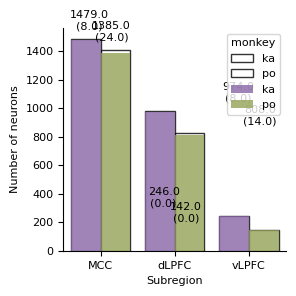

In [5]:
plot_neuron_counts(ds_fb_value_full)

ka - MCC: 1466.0 units, 60 sessions, per session: 24 ± 8
ka - vLPFC: 244.0 units, 12 sessions, per session: 20 ± 7
ka - dLPFC: 964.0 units, 48 sessions, per session: 20 ± 9
po - MCC: 1355.0 units, 53 sessions, per session: 26 ± 9
po - vLPFC: 140.0 units, 7 sessions, per session: 20 ± 9
po - dLPFC: 794.0 units, 46 sessions, per session: 17 ± 9
N units all: 4963, nonna: 4963, onlyna: 0.0
N units all: 4963, nonna: 4963, onlyna: 0.0


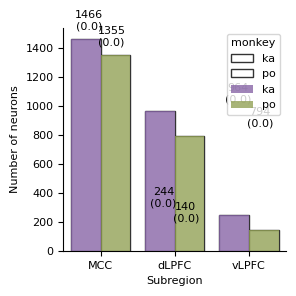

In [6]:
# remove units with nan values (GLM could not be fitted in at least one time bin)
ds_fb_value_full = ds_fb_value_full.dropna(dim="unit", how='any')
ds_fb_value_full
plot_neuron_counts(ds_fb_value_full)

---
# Extract significant units

In [7]:
# per unit info
df_unit_significances = extract_significant_units(ds_fb_value_full, plim=0.05, n_consecutives=4, t_feedback=[.1, 1.1], t_history=[-1.1, -.1])
df_unit_significances

,unit,monkey,session,area,subregion,signif_group,t_vals_feedback,t_vals_value
0,ka_230720_LPFC_05_01,ka,230720,LPFC,dLPFC,None,3.294870,-3.800745
1,ka_230720_LPFC_06_01,ka,230720,LPFC,dLPFC,None,2.005165,-1.845962
2,ka_230720_LPFC_06_02,ka,230720,LPFC,dLPFC,None,-2.407270,2.410472
3,ka_230720_LPFC_06_03,ka,230720,LPFC,dLPFC,None,2.234305,1.939554
4,ka_230720_LPFC_07_01,ka,230720,LPFC,dLPFC,Fb only,-5.826137,2.989814
...,...,...,...,...,...,...,...,...
4958,po_200722_MCC_13_02,po,200722,MCC,MCC,Fb only,5.233635,-2.947756
4959,po_200722_MCC_14_01,po,200722,MCC,MCC,None,1.840394,-1.893934
4960,po_200722_MCC_14_03,po,200722,MCC,MCC,Value only,2.426555,-2.781256
4961,po_200722_MCC_14_02,po,200722,MCC,MCC,Value only,3.304123,-5.024327


In [8]:
# gper session info
prop_units = extract_number_of_signifs(df_unit_significances)
prop_units

,monkey,session,area,subregion,n_units,n_signif_feedback,n_signif_value
0,ka,010720,LPFC,vLPFC,16,9,1
1,ka,010720,MCC,MCC,22,19,14
2,ka,010822,LPFC,dLPFC,25,9,2
3,ka,010822,MCC,MCC,26,9,4
4,ka,010922,LPFC,dLPFC,40,12,4
...,...,...,...,...,...,...,...
223,po,300322,MCC,MCC,15,11,7
224,po,300421,LPFC,dLPFC,10,5,5
225,po,300421,MCC,MCC,22,14,7
226,po,310822,LPFC,dLPFC,23,11,9


---
# Fig. 3c, Proportion of significant units

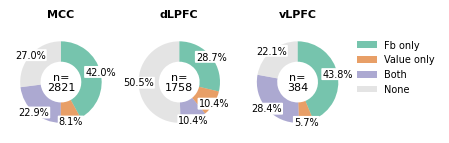

In [9]:
# plot neuron comparison
fig = plot_neuron_comparison(df_unit_significances, save_path=None, paperformat=True)

floc = os.path.join(FIGS_PATH, 'fig3c_significant_units.svg')
fig.savefig(
    floc,
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [10]:
# Export source data (Figure 3c)
from popy.source_data import export_source_data

sd_group_names = {'Fb only': 'Feedback only', 'Value only': 'Value only', 'Both': 'Both', 'None': 'None (neither variable)'}
sd_rows = []
for sd_area in ['MCC', 'dLPFC', 'vLPFC']:
    sd_area_data = df_unit_significances[df_unit_significances['subregion'] == sd_area]
    for sd_group in PALETTE:  # order of the wedges (clockwise from the top), as in plot_neuron_comparison
        sd_n = int((sd_area_data['signif_group'] == sd_group).sum())
        sd_rows.append({'Region': sd_area, 'Coding group': sd_group_names[sd_group], 'Number of units': sd_n,
                        'Percentage of units (%)': 100 * sd_n / len(sd_area_data),
                        'Total number of units (n)': len(sd_area_data)})

export_source_data(
    'Figure 3c', pd.DataFrame(sd_rows),
    'Donut charts: number and percentage of units per region whose spike counts were significantly explained by '
    'feedback only, value only, both, or neither (coefficient of partial determination of the Poisson GLM, permutation '
    'test p < 0.05 in at least 4 consecutive 50-ms bins; feedback: 0.1 to 1.1 s after feedback; value: 1.1 to 0.1 s '
    'before feedback). Units pooled across both monkeys and all sessions; n = total number of units per region '
    '(centre of each donut).'
)

Figure 3c: source data saved (12 rows)


---
# Fig. 3d, Weights of coding


===== Fig. 3d (top marginal, feedback) | monkey: KA, PO | subregion: MCC =====
  Two-sided exact binomial test: proportion of units with negative vs. positive coefficients against 0.5
  n = 1830 units (significant for the regressor, pooled across sessions and monkeys)
  negative: 1117 (61.0%, 95% CI [58.8, 63.3]), positive: 713
  p = 3.111e-21

===== Fig. 3d (right marginal, value) | monkey: KA, PO | subregion: MCC =====
  Two-sided exact binomial test: proportion of units with negative vs. positive coefficients against 0.5
  n = 874 units (significant for the regressor, pooled across sessions and monkeys)
  negative: 479 (54.8%, 95% CI [51.4, 58.1]), positive: 395
  p = 4.964e-03

===== Fig. 3d (top marginal, feedback) | monkey: KA, PO | subregion: dLPFC =====
  Two-sided exact binomial test: proportion of units with negative vs. positive coefficients against 0.5
  n = 688 units (significant for the regressor, pooled across sessions and monkeys)
  negative: 419 (60.9%, 95% CI [57.1, 

/tmp/ipykernel_3446265/1352366248.py:265: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


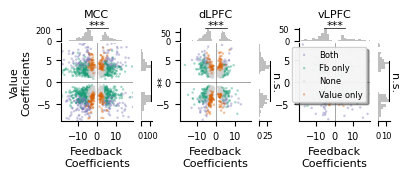

In [11]:
# plot coeffs
fig = plot_coeffs_vs_feedback_value(df_unit_significances, paper_format=True)

savedir = os.path.join(FIGS_PATH, 'fig3d_coeffs_feedback_value.svg')
fig.savefig(
    savedir,
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [12]:
# Export source data (Figure 3d)
from popy.source_data import export_source_data

sd_group_names = {'Fb only': 'Feedback only', 'Value only': 'Value only', 'Both': 'Both', 'None': 'None (neither variable)'}
sd_fb_col, sd_val_col = 'Feedback coefficient (z-value)', 'Value coefficient (z-value)'
sd_dots = pd.DataFrame({
    'Monkey': df_unit_significances['monkey'].astype(str).str.upper(),
    'Session': df_unit_significances['monkey'].astype(str) + '_' + df_unit_significances['session'].astype(str),
    'Unit ID': df_unit_significances['unit'],
    'Recorded area': df_unit_significances['area'],
    'Region (panel)': df_unit_significances['subregion'],
    'Coding group (dot colour)': df_unit_significances['signif_group'].map(sd_group_names),
    sd_fb_col: df_unit_significances['t_vals_feedback'],
    sd_val_col: df_unit_significances['t_vals_value'],
})

# marginal histograms and binomial tests, as in plot_coeffs_vs_feedback_value
sd_hists, sd_tests = [], []
for sd_area, sd_sub_df in df_unit_significances.groupby('subregion'):
    for sd_var, sd_col, sd_groups in [('Feedback (top marginal)', 't_vals_feedback', ['Both', 'Fb only']),
                                      ('Value (right marginal)', 't_vals_value', ['Both', 'Value only'])]:
        sd_tvals = sd_sub_df.loc[sd_sub_df['signif_group'].isin(sd_groups), sd_col]
        sd_counts, sd_edges = np.histogram(sd_tvals, bins=50)
        sd_hists.append(pd.DataFrame({'Region': sd_area, 'Variable': sd_var, 'Bin start (z-value)': sd_edges[:-1],
                                      'Bin end (z-value)': sd_edges[1:], 'Number of units': sd_counts}))
        sd_pos, sd_neg = int((sd_tvals > 0).sum()), int((sd_tvals < 0).sum())
        sd_p = binomtest(sd_pos, sd_pos + sd_neg, p=0.5, alternative='two-sided').pvalue
        sd_tests.append({'Region': sd_area, 'Variable': sd_var, 'Units with positive coefficient': sd_pos,
                         'Units with negative coefficient': sd_neg, 'n (units)': sd_pos + sd_neg,
                         'p (two-sided binomial test vs. 0.5)': sd_p,
                         'Marker': '***' if sd_p < 0.001 else '**' if sd_p < 0.01 else '*' if sd_p < 0.05 else 'n.s.'})

sd_n_outside = int(((sd_dots[sd_fb_col].abs() > 19) | (sd_dots[sd_val_col].abs() > 9)).sum())
export_source_data(
    'Figure 3d',
    {'Units (dots)': sd_dots, 'Marginal histograms': pd.concat(sd_hists, ignore_index=True),
     'Binomial tests (markers)': pd.DataFrame(sd_tests)},
    'Each dot is one unit (pooled across monkeys and sessions; one panel per region): GLM coefficients of feedback (x) '
    'and value (y), as z-values (coefficient / standard error of the Poisson GLM) at the time bin with the largest '
    'absolute value (feedback: 0.1 to 1.1 s after feedback; value: 1.1 to 0.1 s before feedback); dot colour = coding '
    'group as in Fig. 3c. Marginals: histograms (50 bins) of the feedback coefficients of feedback-coding units '
    '(Feedback only + Both; top) and of the value coefficients of value-coding units (Value only + Both; right). '
    'Markers: two-sided exact binomial test of the numbers of units with positive vs. negative coefficients against 0.5 '
    f'(***p < 0.001, **p < 0.01, n.s. not significant). {sd_n_outside} of {len(sd_dots)} dots lie outside the axis '
    'limits (feedback -19 to 19, value -9 to 9) and are not visible.'
)

Figure 3d: source data saved (4963 rows, 300 rows, 6 rows)


---
# Fig. 3e, Recording sites

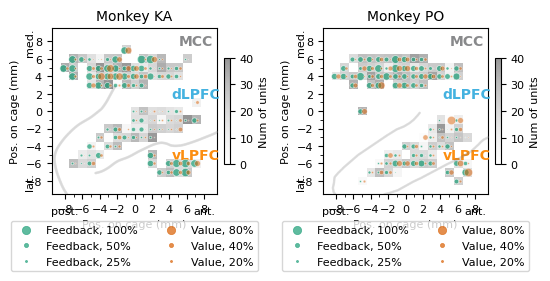

In [13]:
# plot on cortical surface
var = "n_units"
fig, axs = plot_on_cortical_grid(
    prop_units,
    column_to_show=var,
    title=None, 
    palette=PALETTE,
    bar_title="Num of units",
    paper_format=True)

# save figure

floc = os.path.join(FIGS_PATH, "fig3e_cortical_grid.svg")
fig.savefig(floc, dpi=300, bbox_inches="tight", transparent=True)

In [14]:
# Export source data (Figure 3e)
from popy.source_data import export_source_data
from popy.plotting.plot_cortical_grid import _get_grid_location

# values per grid position as filled in plot_on_cortical_grid: one session per position (if several sessions were
# recorded at the same position, the one with the highest proportion of value-coding units)
sd_tables = {}
for sd_monkey in ['ka', 'po']:
    sd_sites = {}
    for (sd_session, sd_area), sd_sub_df in prop_units.loc[prop_units.monkey == sd_monkey].groupby(['session', 'area']):
        sd_loc = _get_grid_location(sd_monkey, sd_session, sd_area)
        if np.isnan(sd_loc).any():
            continue
        sd_n_units = sd_sub_df['n_units'].values[0]
        sd_site = {
            'Horizontal position (mm; posterior - / anterior +)': -sd_loc[0],  # plotted at x = -grid x
            'Vertical position (mm; lateral - / medial +)': sd_loc[1],
            'Region': sd_sub_df['subregion'].values[0],
            'Session': f'{sd_monkey}_{sd_session}',
            'Number of units (grey scale)': sd_n_units,
            'Number of feedback-coding units': sd_sub_df['n_signif_feedback'].values[0],
            'Number of value-coding units': sd_sub_df['n_signif_value'].values[0],
            'Proportion of feedback-coding units (green dot)': sd_sub_df['n_signif_feedback'].values[0] / sd_n_units,
            'Proportion of value-coding units (orange dot)': sd_sub_df['n_signif_value'].values[0] / sd_n_units,
        }
        if (sd_loc not in sd_sites
                or sd_site['Proportion of value-coding units (orange dot)'] > sd_sites[sd_loc]['Proportion of value-coding units (orange dot)']):
            sd_sites[sd_loc] = sd_site
    sd_tables[f'Monkey {sd_monkey.upper()}'] = pd.DataFrame(list(sd_sites.values())).sort_values(
        ['Region', 'Vertical position (mm; lateral - / medial +)', 'Horizontal position (mm; posterior - / anterior +)'],
        ascending=[True, False, True], ignore_index=True)

export_source_data(
    'Figure 3e', sd_tables,
    'Recording sites on the 1-mm chamber grid of each monkey, at their plotted positions (mm; horizontal: posterior to '
    'anterior, vertical: lateral to medial). Grey squares: number of units recorded at the site (grey scale 0 to 40, '
    'saturating above 40). Green (left) and orange (right) dots: proportion of feedback-coding (Feedback only + Both) '
    'and value-coding (Value only + Both) units at the site (as in Fig. 3c); dot diameter proportional to the '
    'proportion, capped at 100% (feedback) and 80% (value). If several sessions were recorded at the same site, the '
    'session with the highest proportion of value-coding units is drawn (listed here). Grid positions not listed have '
    'no recordings.'
)

Figure 3e: source data saved (93 rows, 86 rows)
